In [18]:
import torch
import torch.nn as nn
from torchvision.transforms import v2
from torch.utils.data import DataLoader

from tqdm.auto import tqdm
import matplotlib.pyplot as plt

from datasets import load_dataset, load_from_disk
from preprocessing import preprocess_pipeline, remove_redundant_columns

In [19]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


In [20]:
SEED = 42

In [ ]:
class ConvAutoencoder(nn.Module):
    def __init__(self, img_size = 256, latent_dim = 128) -> None:
        super().__init__()
        final_channels_count = 128
        final_img_size = img_size // 16
        flatten_in_size = final_channels_count * final_img_size * final_img_size 

        self.encoder = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2,2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2,2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2,2),
            nn.Conv2d(64, final_channels_count, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2,2),
            nn.Flatten(),
            nn.Linear(flatten_in_size, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, flatten_in_size), nn.ReLU(inplace=True),
            nn.Unflatten(1, (final_channels_count, final_img_size, final_img_size)),
            nn.ConvTranspose2d(final_channels_count, 64, kernel_size=3, padding=1, output_padding=1, stride=2), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, kernel_size=3, padding=1, output_padding=1, stride=2), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 16, kernel_size=3, padding=1, output_padding=1, stride=2), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(16, 3, kernel_size=3, padding=1, output_padding=1, stride=2), nn.Sigmoid(),
        )

    def encode(self, x):
        return self.encoder(x)
    
    def decode(self, x):
        return self.decoder(x)
        
    def forward(self, x):
        x = self.encode(x)
        x = self.decode(x)
        return x

In [22]:
from pathlib import Path
from datasets import load_dataset, load_from_disk

processed_dir = Path("data/wikiart_train_processed")

if processed_dir.exists():
    ds_full = load_from_disk(str(processed_dir))
else:
    ds_full = load_dataset(
        "Artificio/WikiArt_Full",
        split="train",
        cache_dir="data",
    )
    ds_full = preprocess_pipeline(ds_full)
    ds_full = remove_redundant_columns(ds_full)
    ds_full.save_to_disk(str(processed_dir))

In [23]:
split = ds_full.train_test_split(test_size=0.2, seed=SEED)
ds_train = split['train']
second_split = split['test'].train_test_split(test_size=0.5, seed=SEED)
ds_val = second_split['train']
ds_test = second_split['test']

In [24]:
BATCH_SIZE = 64

In [25]:
basic_trans = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(dtype=torch.float32, scale=True)
])

In [26]:
train_dataloader = DataLoader(ds_train.select_columns("image").with_transform(basic_trans), 
                              batch_size=BATCH_SIZE, 
                              num_workers=2,
                              persistent_workers=True,
                              pin_memory=torch.cuda.is_available(),
                              shuffle=True)

val_dataloader = DataLoader(ds_val.select_columns("image").with_transform(basic_trans), 
                            num_workers=2,
                            persistent_workers=True,
                            batch_size=BATCH_SIZE, 
                            pin_memory=torch.cuda.is_available())

test_dataloader = DataLoader(ds_test.select_columns("image").with_transform(basic_trans), 
                            num_workers=2,
                            persistent_workers=True,
                            batch_size=BATCH_SIZE, 
                            pin_memory=torch.cuda.is_available())

In [27]:
LEARNING_RATE = 0.001
EPOCHS = 10

model = ConvAutoencoder().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_fn = nn.MSELoss()

In [28]:
train_loss_hist = []
val_loss_hist = []

In [29]:
epoch_bar = tqdm(range(EPOCHS), desc="Epochs")
for epoch in epoch_bar:
    # ======= TRAIN =======
    model.train()
    train_loss, n = 0.0, 0
    train_bar = tqdm(train_dataloader, desc="Training", leave=False)
    for batch in train_bar:
        # print(batch["image"].shape)
        x = batch["image"].to(device, non_blocking=torch.cuda.is_available())
        # print(x.shape)
        out = model(x)
        # print(out.shape)
        loss : torch.Tensor = loss_fn(out, x)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * x.size(0)
        n += x.size(0)
        train_bar.set_postfix(loss=f"{train_loss / n:.4f}")
    train_loss /= n
    train_loss_hist.append(train_loss)

    # ======= VALID =======
    model.eval()
    val_loss, n = 0.0, 0
    val_bar = tqdm(val_dataloader, desc="Validation", leave=False)
    with torch.inference_mode():
        for batch in val_bar:
            x = batch["image"].to(device, non_blocking=torch.cuda.is_available())
            out_eval = model(x)
            loss_val = loss_fn(out_eval, x)

            val_loss += loss_val.item() * x.size(0)
            n += x.size(0)
    val_loss /= n
    val_loss_hist.append(val_loss)

Epochs:   0%|          | 0/10 [00:00<?, ?it/s]

Training:   0%|          | 0/1287 [00:00<?, ?it/s]

Validation:   0%|          | 0/161 [00:00<?, ?it/s]

Training:   0%|          | 0/1287 [00:00<?, ?it/s]

Validation:   0%|          | 0/161 [00:00<?, ?it/s]

Training:   0%|          | 0/1287 [00:00<?, ?it/s]

... (11 outputs left out)

Training:   0%|          | 0/1287 [00:00<?, ?it/s]

Validation:   0%|          | 0/161 [00:00<?, ?it/s]

Training:   0%|          | 0/1287 [00:00<?, ?it/s]

Validation:   0%|          | 0/161 [00:00<?, ?it/s]

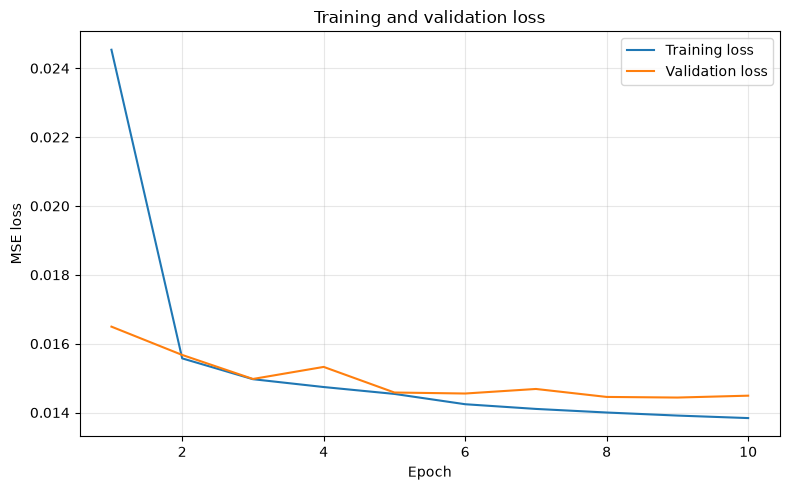

In [30]:
epochs = range(1, len(train_loss_hist) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss_hist, label="Training loss")
plt.plot(epochs, val_loss_hist, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Training and validation loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

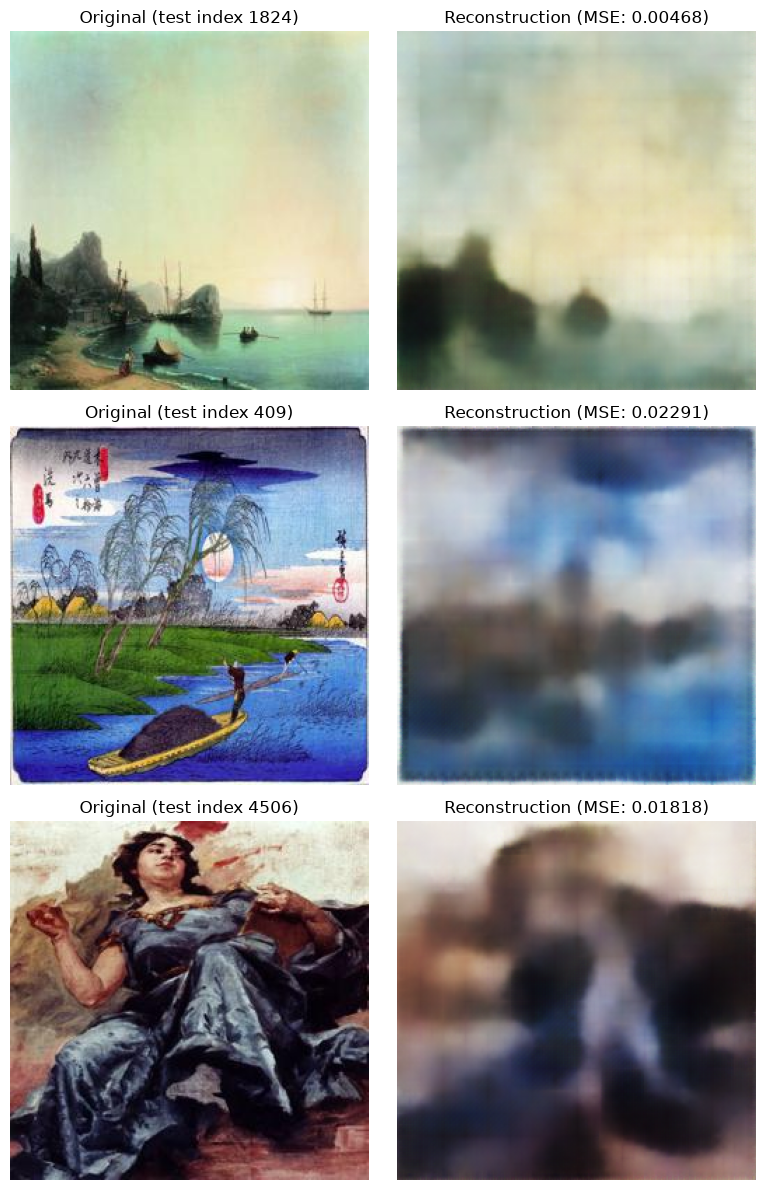

In [31]:
import random
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

# Change the seed if you want a different reproducible sample each time.
indices = random.Random(SEED).sample(range(len(ds_test)), k=3)

model.eval()
fig, axes = plt.subplots(len(indices), 2, figsize=(8, 4 * len(indices)), squeeze=False)

with torch.inference_mode():
    for row, idx in enumerate(indices):
        image = ds_test[idx]["image"]
        x = basic_trans(image).unsqueeze(0).to(device)

        output = model(x)
        mse = F.mse_loss(output, x).item()

        original = x.squeeze(0).cpu().clamp(0, 1)
        reconstruction = output.squeeze(0).cpu().clamp(0, 1)

        axes[row, 0].imshow(original.permute(1, 2, 0).numpy())
        axes[row, 0].set_title(f"Original (test index {idx})")

        axes[row, 1].imshow(reconstruction.permute(1, 2, 0).numpy())
        axes[row, 1].set_title(f"Reconstruction (MSE: {mse:.5f})")

        axes[row, 0].axis("off")
        axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [32]:
with torch.inference_mode():    
    img = ds_test[0]["image"]
    x = basic_trans(img).unsqueeze(0).to(device)
    print(x.shape)
    print("======")
    print(model.encode(x).shape)
    print("======")
    print(model(x).shape)

torch.Size([1, 3, 256, 256])
torch.Size([1, 128])
torch.Size([1, 3, 256, 256])


In [33]:
from pathlib import Path

weights_dir = Path("models_weights")
weights_dir.mkdir(parents=True, exist_ok=True)

weights_path = weights_dir / "conv_autoencoder.pth"
torch.save(model.state_dict(), weights_path)

print(f"Saved weights to: {weights_path.resolve()}")

Saved weights to: C:\Users\MatG\Desktop\UniStuff\MAGI\Semestr II\UczenieNienadzorowane\Project\notebooks\matg\models_weights\conv_autoencoder.pth
